# Smart Waste-Bin System: predicting time until the bin is full
**Algorithm:** Multiple Linear Regression | **Target:** `hours_to_full`

Steps: 1 load data, 2 prepare and build the target, 3 clean and visualize, 4 store in SQLite,
5 train, 6 evaluate and improve, 7 save the model for the app.

**Data note:** the Kaggle smart-city dataset (synthetic) has one waste bin with hourly fill %, duplicated rows,
missing values and sensor spikes. It has no weight and no collection record, so weight is simulated and collection
events are detected from sharp drops in smoothed fill %. "Full" is set from the bin's typical peak fill (see below).

In [2]:
# !pip install -q pandas scikit-learn matplotlib joblib   # uncomment in Colab
import json, sqlite3
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = "smart_city_sensor_data.csv"   # download from Kaggle, put next to this notebook
FULL_THRESHOLD = "auto"  # "auto" = 90% of the typical peak fill reached before collection, or a number like 80
DROP_THRESHOLD = 20      # a fall of more than 20 points (on smoothed fill) = bin was emptied
SPIKE_LIMIT = 20         # a reading more than 20 points from its neighbours' median = sensor spike
MIN_HOURS = 1            # avoid division by ~0 right after collection
BIN_CAPACITY_KG = 25     # simulated weight of a 100% full bin
OUT = Path("artifacts"); OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(42)

## 1. Load data
Uses the real CSV if it exists AND shows fill-and-empty cycles. Otherwise it falls back to a clearly
labelled synthetic fill process. The source used is saved in `metrics.json` and shown in the app.

In [3]:
COLS = ['City','Sensor_ID','Lat','Lon','Timestamp','Sensor_Type','Street_Type',
        'Nearby','Vehicles','kWh','Fill','Noise']

def load_real(path):
    df = pd.read_csv(path)
    df.columns = COLS
    df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
    return df[df.Sensor_Type == 'Atık Sensörü'][['Sensor_ID','Timestamp','Fill']].copy()

def synthetic_waste(n_bins=4):
    ts = pd.date_range("2023-01-01", "2024-12-31 23:00", freq="h")
    rows = []
    for b in range(n_bins):
        factor, fill, level = rng.uniform(0.8, 1.3), rng.uniform(0, 10), rng.uniform(85, 100)
        for t in ts:
            rate = (0.5 + 1.5*np.exp(-((t.hour-13)/4)**2)) * (1.3 if t.weekday() >= 5 else 1) \
                   * factor * rng.lognormal(0, 0.25)
            fill = min(fill + rate, 100)
            rows.append((f"BIN-{b+1}", t, fill))
            if fill >= level:
                fill, level = rng.uniform(0, 5), rng.uniform(85, 100)
    return pd.DataFrame(rows, columns=['Sensor_ID','Timestamp','Fill'])

def clean_series(w):
    """Dedupe, remove impossible values and spikes, fill short gaps, smooth, and number the fill cycles."""
    w = (w.dropna(subset=['Timestamp']).drop_duplicates(['Sensor_ID','Timestamp'], keep='first')
           .sort_values(['Sensor_ID','Timestamp']).reset_index(drop=True))
    w.loc[(w.Fill < 0) | (w.Fill > 100), 'Fill'] = np.nan
    med = w.groupby('Sensor_ID')['Fill'].transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
    w.loc[(w.Fill - med).abs() > SPIKE_LIMIT, 'Fill'] = np.nan                       # isolated spikes
    w['Fill'] = w.groupby('Sensor_ID')['Fill'].transform(lambda s: s.interpolate(limit=6, limit_area='inside'))
    w = w.dropna(subset=['Fill']).copy()
    w['smooth'] = w.groupby('Sensor_ID')['Fill'].transform(lambda s: s.rolling(5, center=True, min_periods=1).median())
    w['cycle'] = (w.groupby('Sensor_ID')['smooth'].diff() < -DROP_THRESHOLD).groupby(w['Sensor_ID']).cumsum()
    return w

def quality(w):
    c = clean_series(w)
    drops = int(c.groupby('Sensor_ID')['cycle'].max().sum())
    ac = c.groupby('Sensor_ID')['smooth'].apply(lambda s: s.autocorr(1)).mean()
    return drops, ac

data_source = "synthetic fallback"
raw = None
if Path(DATA_PATH).exists():
    cand = load_real(DATA_PATH)
    drops, ac = quality(cand)
    print(f"Real waste rows: {len(cand)} | collections detected: {drops} | lag-1 autocorr: {ac:.2f}")
    if drops >= 30 and ac >= 0.7:
        raw, data_source = cand, "Kaggle smart-city dataset (waste sensors)"
    else:
        print("WARNING: real data shows no clear fill/empty cycles, not suitable for 'time until full'.")
else:
    print("WARNING: CSV not found.")
if raw is None:
    print(">>> Using SYNTHETIC fill data. State this clearly in your report. <<<")
    raw = synthetic_waste()
print("Data source:", data_source, "| raw rows:", len(raw), "| bins:", raw.Sensor_ID.nunique())

Real waste rows: 35088 | collections detected: 103 | lag-1 autocorr: 0.97
Data source: Kaggle smart-city dataset (waste sensors) | raw rows: 35088 | bins: 1


## 2. Prepare data and build the target

In [4]:
w = clean_series(raw)
w = w[w.cycle > 0].copy()                                                         # first cycle has unknown start
w['cycle_start'] = w.groupby(['Sensor_ID','cycle'])['Timestamp'].transform('min')
w['hours_since_collection'] = (w.Timestamp - w.cycle_start).dt.total_seconds()/3600

peak = w.groupby(['Sensor_ID','cycle'])['smooth'].max()
FULL_LEVEL = round(0.9 * peak.median()) if FULL_THRESHOLD == "auto" else FULL_THRESHOLD
print(f"Typical peak before collection: {peak.median():.0f}% -> 'full' level used: {FULL_LEVEL}%")

full_time = w[w.smooth >= FULL_LEVEL].groupby(['Sensor_ID','cycle'])['Timestamp'].min().rename('full_time')
w = w.join(full_time, on=['Sensor_ID','cycle'])
w['hours_to_full'] = (w.full_time - w.Timestamp).dt.total_seconds()/3600        # TARGET
w = w[(w.hours_to_full > 0) & (w.hours_since_collection >= MIN_HOURS)].copy()     # drops NaN and rows already full

w['weight_kg'] = (w.Fill/100 * BIN_CAPACITY_KG * rng.normal(1, 0.08, len(w))).clip(lower=0)   # SIMULATED
w['hour'] = w.Timestamp.dt.hour
w['is_weekend'] = (w.Timestamp.dt.weekday >= 5).astype(int)
w['avg_fill_rate'] = w.Fill / w.hours_since_collection
w = w.rename(columns={'Fill': 'fill_pct'})

FEATURES = ['fill_pct','weight_kg','hours_since_collection','avg_fill_rate','hour','is_weekend']
TARGET = 'hours_to_full'
print(f"Usable rows: {len(w)} | cycles: {w.groupby(['Sensor_ID','cycle']).ngroups}")
w[FEATURES + [TARGET]].describe().round(2)

Typical peak before collection: 51% -> 'full' level used: 46%
Usable rows: 14383 | cycles: 97


,fill_pct,weight_kg,hours_since_collection,avg_fill_rate,hour,is_weekend,hours_to_full
count,14383.00,14383.00,14383.00,14383.00,14383.00,14383.0,14383.00
mean,22.38,5.59,74.80,0.33,11.25,0.2,74.80
std,13.42,3.40,43.08,0.42,6.90,0.4,43.08
min,0.00,0.00,1.00,0.00,0.00,0.0,1.00
25%,11.18,2.77,38.00,0.25,5.00,0.0,38.00
50%,22.41,5.57,75.00,0.30,11.00,0.0,75.00
75%,33.21,8.27,112.00,0.35,17.00,0.0,112.00
max,57.26,16.30,164.00,14.03,23.00,1.0,164.00


## 3. Clean and visualize

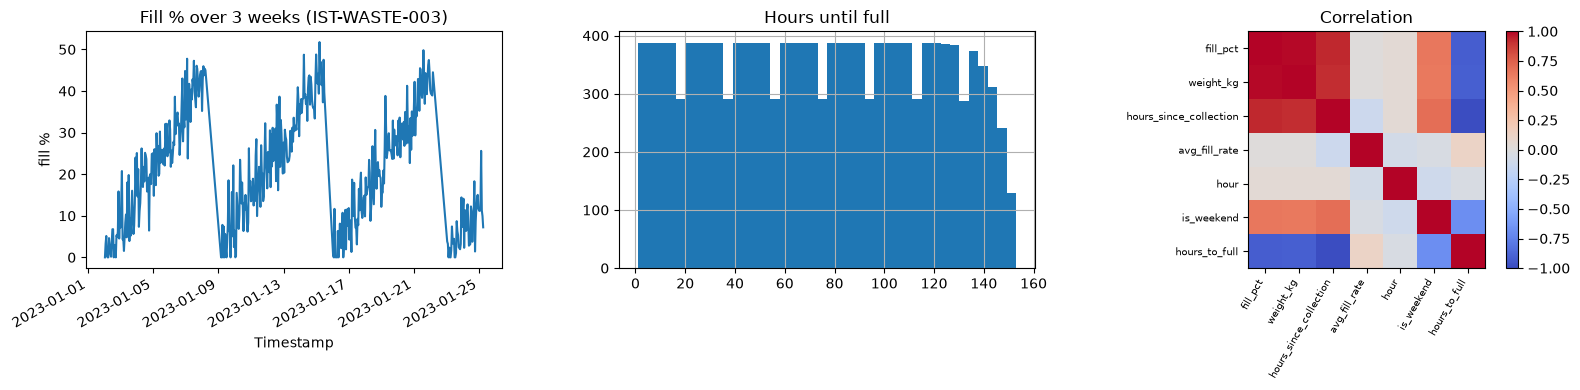

In [5]:
w = w[w.hours_to_full < w.hours_to_full.quantile(0.995)]          # trim extreme long cycles
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sid = w.Sensor_ID.iloc[0]
s = w[w.Sensor_ID == sid].set_index('Timestamp')['fill_pct'].iloc[:24*21]
s.plot(ax=ax[0], title=f"Fill % over 3 weeks ({sid})"); ax[0].set_ylabel("fill %")
w[TARGET].hist(bins=40, ax=ax[1]); ax[1].set_title("Hours until full")
corr = w[FEATURES + [TARGET]].corr()
im = ax[2].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[2].set_xticks(range(len(corr))); ax[2].set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=7)
ax[2].set_yticks(range(len(corr))); ax[2].set_yticklabels(corr.columns, fontsize=7); ax[2].set_title("Correlation")
plt.colorbar(im, ax=ax[2]); plt.tight_layout(); plt.savefig(OUT/"eda.png", dpi=120); plt.show()

## 4. Store in SQLite

In [6]:
con = sqlite3.connect(OUT/"waste_bin.db")
store = w[['Sensor_ID','Timestamp'] + FEATURES + [TARGET]].copy()
store['Timestamp'] = store['Timestamp'].astype(str)
store.to_sql("waste_readings", con, if_exists="replace", index=False)
print(pd.read_sql("SELECT COUNT(*) AS rows FROM waste_readings", con))
con.close()

    rows
0  14295


## 5. Train (Multiple Linear Regression)
Time-based split: the oldest 80% trains, the newest 20% tests.

In [7]:
w = w.sort_values('Timestamp')
cut = w.Timestamp.quantile(0.8)
train, test = w[w.Timestamp <= cut], w[w.Timestamp > cut]
Xtr, ytr, Xte, yte = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]

mlr = LinearRegression().fit(Xtr, ytr)
print("Train rows:", len(train), "| Test rows:", len(test))
print(pd.Series(mlr.coef_, index=FEATURES).round(3), "\nIntercept:", round(mlr.intercept_, 3))

Train rows: 11436 | Test rows: 2859
fill_pct                 -0.020
weight_kg                 0.068
hours_since_collection   -0.991
avg_fill_rate             0.001
hour                      0.007
is_weekend                1.211
dtype: float64 
Intercept: 148.375


## 6. Evaluate and improve

                        MAE_h  RMSE_h     R2
Baseline (fill % only)  12.93   16.31  0.857
MLR (all features)       4.81    6.28  0.979
Ridge (comparison)       4.81    6.29  0.979
Time-series CV R2: [0.955 0.987 0.983 0.978 0.972] mean 0.975


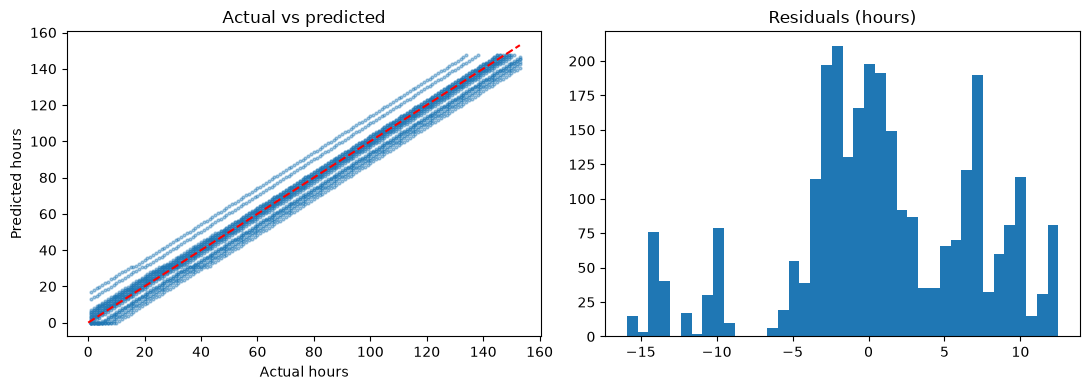

In [8]:
def score(model, cols):
    p = np.clip(model.predict(Xte[cols]), 0, None)
    return {"MAE_h": round(mean_absolute_error(yte, p), 2),
            "RMSE_h": round(mean_squared_error(yte, p) ** 0.5, 2),
            "R2": round(r2_score(yte, p), 3)}

base_cols = ['fill_pct']
baseline = LinearRegression().fit(Xtr[base_cols], ytr)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xtr, ytr)
results = pd.DataFrame({
    "Baseline (fill % only)": score(baseline, base_cols),
    "MLR (all features)": score(mlr, FEATURES),
    "Ridge (comparison)": score(ridge, FEATURES)}).T
print(results)
cv = cross_val_score(LinearRegression(), Xtr, ytr, cv=TimeSeriesSplit(5), scoring="r2")
print("Time-series CV R2:", cv.round(3), "mean", cv.mean().round(3))

pred = np.clip(mlr.predict(Xte), 0, None)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yte, pred, s=4, alpha=.4); lim = [0, max(yte.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual hours"); ax[0].set_ylabel("Predicted hours"); ax[0].set_title("Actual vs predicted")
ax[1].hist(yte - pred, bins=40); ax[1].set_title("Residuals (hours)")
plt.tight_layout(); plt.savefig(OUT/"evaluation.png", dpi=120); plt.show()

## 7. Save model and metrics for the app

In [9]:
final = LinearRegression().fit(w[FEATURES], w[TARGET])        # refit on all data
joblib.dump({"model": final, "features": FEATURES,
             "full_threshold": FULL_LEVEL, "min_hours": MIN_HOURS}, OUT/"bin_model.pkl")
metrics = {"data_source": data_source, "rows": int(len(w)), "full_level_pct": float(FULL_LEVEL), "weight": "simulated from fill %",
           "baseline": results.loc["Baseline (fill % only)"].to_dict(),
           "mlr": results.loc["MLR (all features)"].to_dict(),
           "ridge": results.loc["Ridge (comparison)"].to_dict(),
           "coefficients": dict(zip(FEATURES, map(float, final.coef_))),
           "intercept": float(final.intercept_)}
json.dump(metrics, open(OUT/"metrics.json", "w"), indent=2)
print("Saved:", [p.name for p in OUT.iterdir()])

Saved: ['bin_model.pkl', 'eda.png', 'evaluation.png', 'metrics.json', 'waste_bin.db']
